In [15]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Load datasets
tips = sns.load_dataset("tips")
flights = sns.load_dataset("flights")
mpg = sns.load_dataset("mpg")
penguins = sns.load_dataset("penguins")
titanic = sns.load_dataset("titanic")

print("Datasets loaded successfully!")

Datasets loaded successfully!


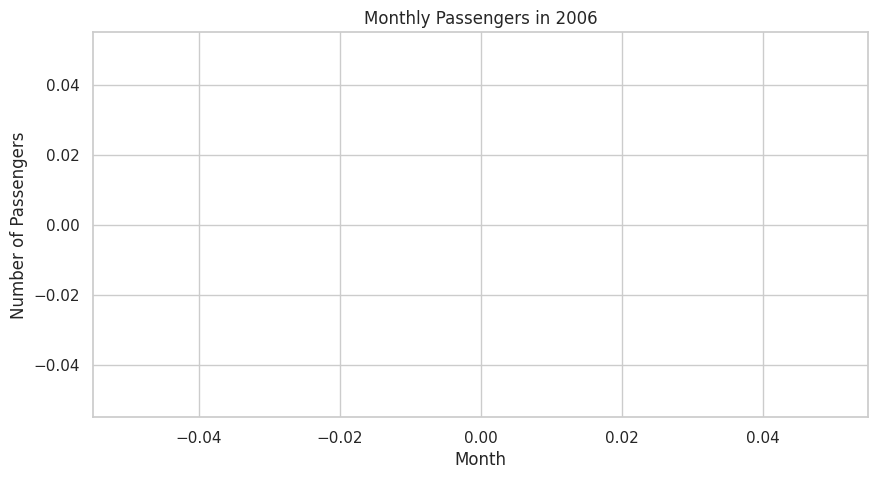

In [16]:
# TASK 1: Line Plot

year_data = flights[flights["year"] == 2006]

plt.figure(figsize=(10, 5))

plt.plot(
    year_data["month"],
    year_data["passengers"],
    marker="o"
)

plt.title("Monthly Passengers in 2006")
plt.xlabel("Month")
plt.ylabel("Number of Passengers")

plt.grid(True)

plt.show()

Insight:
The number of passengers varies throughout the year, with passenger traffic generally increasing during the summer months and decreasing during the colder months.

/tmp/ipykernel_3383/2718497619.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  average_bill = tips.groupby("day")["total_bill"].mean()


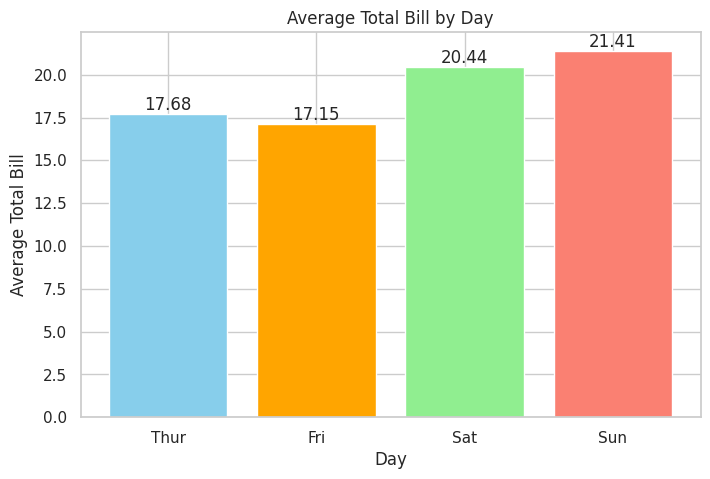

In [17]:
# TASK 2: Bar Chart

average_bill = tips.groupby("day")["total_bill"].mean()

days = average_bill.index
values = average_bill.values

plt.figure(figsize=(8, 5))

bars = plt.bar(
    days,
    values,
    color=["skyblue", "orange", "lightgreen", "salmon"]
)

plt.title("Average Total Bill by Day")
plt.xlabel("Day")
plt.ylabel("Average Total Bill")

# Add value labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom"
    )

plt.show()

Insight:
The average total bill differs across the days of the week. Sunday and Saturday generally have higher average bills compared with some weekdays.

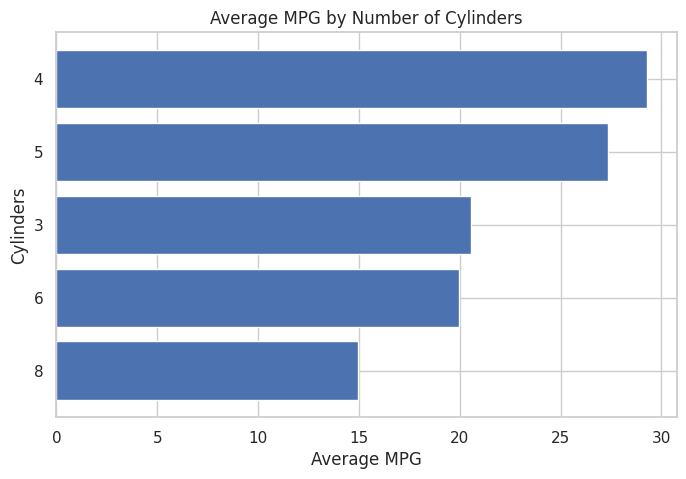

In [18]:
# TASK 3: Horizontal Bar Chart

average_mpg = (
    mpg.groupby("cylinders")["mpg"]
    .mean()
    .sort_values(ascending=True)
)

plt.figure(figsize=(8, 5))

plt.barh(
    average_mpg.index.astype(str),
    average_mpg.values
)

plt.title("Average MPG by Number of Cylinders")
plt.xlabel("Average MPG")
plt.ylabel("Cylinders")

plt.show()

Insight:
Vehicles with fewer cylinders generally have higher average MPG, while vehicles with more cylinders tend to have lower fuel efficiency.

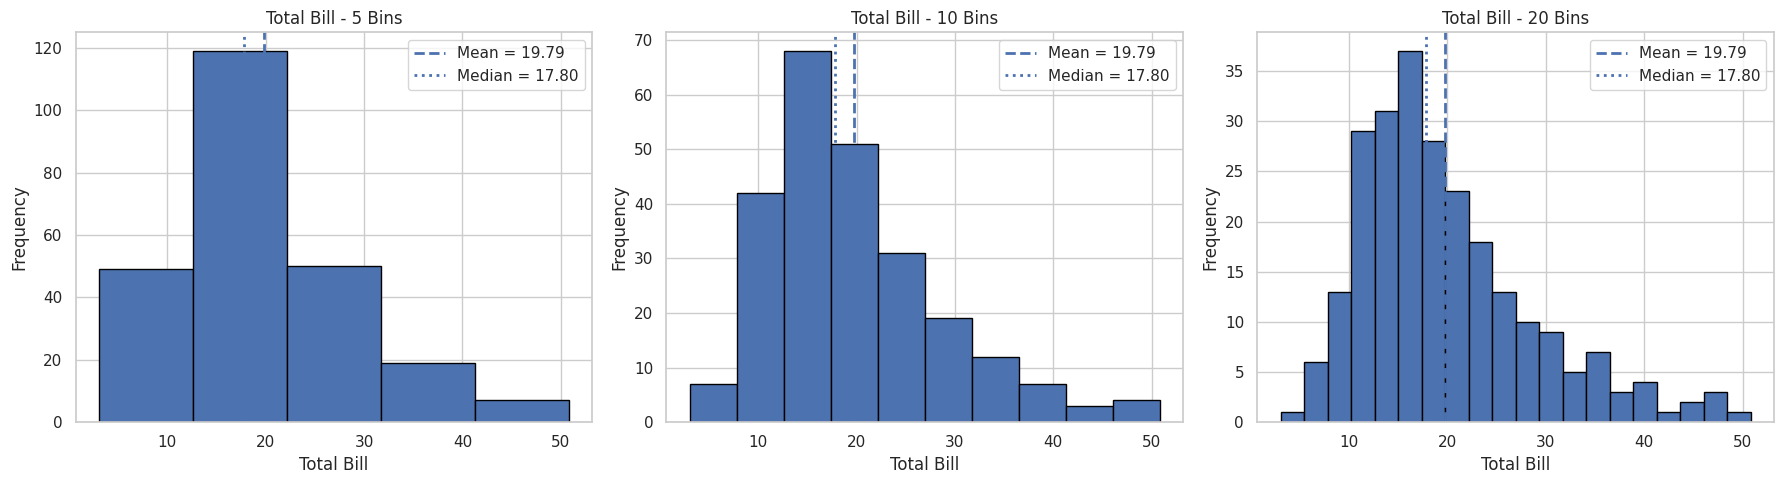

In [19]:
# TASK 4: Histograms with Different Bin Sizes

mean_bill = tips["total_bill"].mean()
median_bill = tips["total_bill"].median()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

bin_sizes = [5, 10, 20]

for ax, bins in zip(axes, bin_sizes):
    ax.hist(tips["total_bill"], bins=bins, edgecolor="black")

    ax.axvline(
        mean_bill,
        linestyle="--",
        linewidth=2,
        label=f"Mean = {mean_bill:.2f}"
    )

    ax.axvline(
        median_bill,
        linestyle=":",
        linewidth=2,
        label=f"Median = {median_bill:.2f}"
    )

    ax.set_title(f"Total Bill - {bins} Bins")
    ax.set_xlabel("Total Bill")
    ax.set_ylabel("Frequency")
    ax.legend()

plt.tight_layout()
plt.show()

Insight:
Changing the number of bins changes how detailed the distribution appears. The mean and median are close, suggesting that the total bill distribution is not extremely skewed.

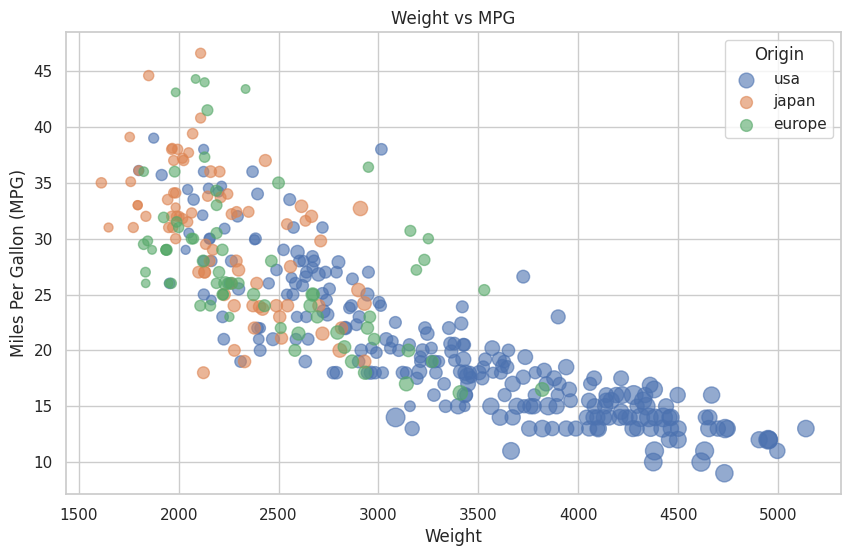

In [20]:
# TASK 5: Scatter Plot

plt.figure(figsize=(10, 6))

for origin in mpg["origin"].dropna().unique():

    data = mpg[mpg["origin"] == origin]

    plt.scatter(
        data["weight"],
        data["mpg"],
        s=data["horsepower"] * 0.8,
        alpha=0.6,
        label=origin
    )

plt.title("Weight vs MPG")
plt.xlabel("Weight")
plt.ylabel("Miles Per Gallon (MPG)")
plt.legend(title="Origin")

plt.show()

Insight:
There is a clear negative relationship between vehicle weight and MPG. Heavier vehicles generally have lower fuel efficiency.

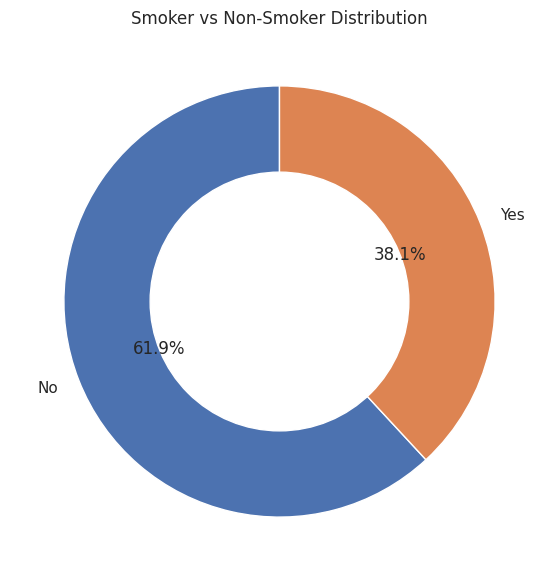

In [21]:
# TASK 6: Donut Chart

smoker_counts = tips["smoker"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    smoker_counts,
    labels=smoker_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

# Create donut hole
centre_circle = plt.Circle((0, 0), 0.60, fc="white")

fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title("Smoker vs Non-Smoker Distribution")

plt.show()

Insight:
The dataset contains more non-smokers than smokers, meaning non-smokers represent the larger share of the customers.

/tmp/ipykernel_3383/1238199609.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  average_bill = tips.groupby("day")["total_bill"].mean()


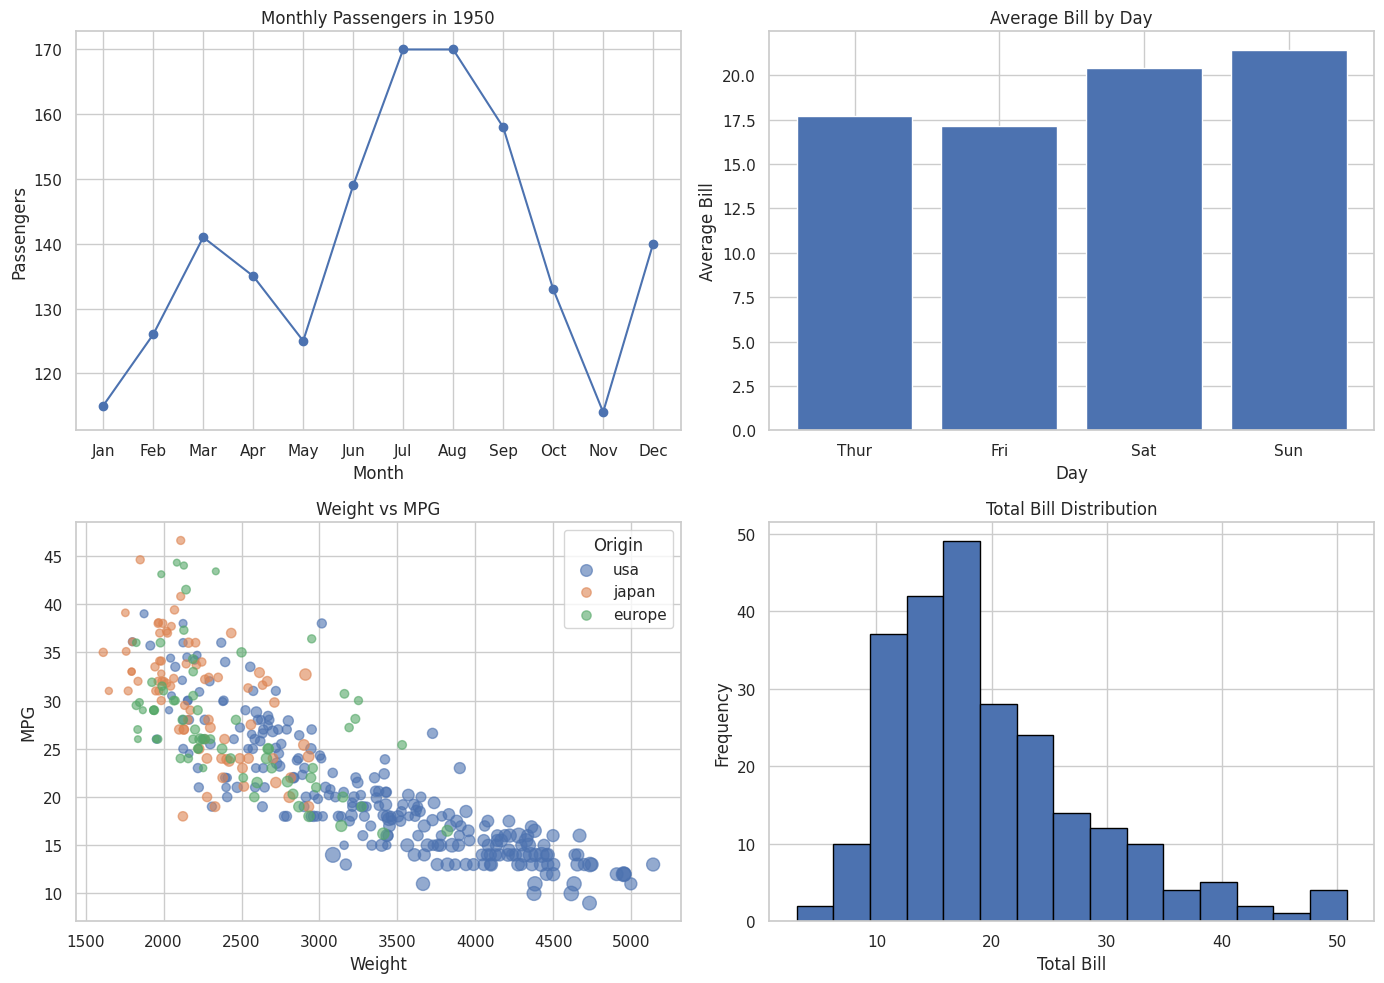

In [22]:
# TASK 7: Mini Dashboard

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Line Plot

year_data = flights[flights["year"] == 1950]

axes[0, 0].plot(
    year_data["month"],
    year_data["passengers"],
    marker="o"
)

axes[0, 0].set_title("Monthly Passengers in 1950")
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylabel("Passengers")
axes[0, 0].grid(True)

# Plot 2: Bar Chart

average_bill = tips.groupby("day")["total_bill"].mean()

axes[0, 1].bar(
    average_bill.index,
    average_bill.values
)

axes[0, 1].set_title("Average Bill by Day")
axes[0, 1].set_xlabel("Day")
axes[0, 1].set_ylabel("Average Bill")

# Plot 3: Scatter Plot

for origin in mpg["origin"].dropna().unique():

    data = mpg[mpg["origin"] == origin]

    axes[1, 0].scatter(
        data["weight"],
        data["mpg"],
        s=data["horsepower"] * 0.5,
        alpha=0.6,
        label=origin
    )

axes[1, 0].set_title("Weight vs MPG")
axes[1, 0].set_xlabel("Weight")
axes[1, 0].set_ylabel("MPG")
axes[1, 0].legend(title="Origin")

# Plot 4: Histogram

axes[1, 1].hist(
    tips["total_bill"],
    bins=15,
    edgecolor="black"
)

axes[1, 1].set_title("Total Bill Distribution")
axes[1, 1].set_xlabel("Total Bill")
axes[1, 1].set_ylabel("Frequency")


plt.tight_layout()

# Save dashboard
plt.savefig(
    "matplotlib_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Insight:
The dashboard summarizes different aspects of the datasets, including passenger trends, restaurant bills, vehicle efficiency and bill distribution in a single figure.

**SEABORN**

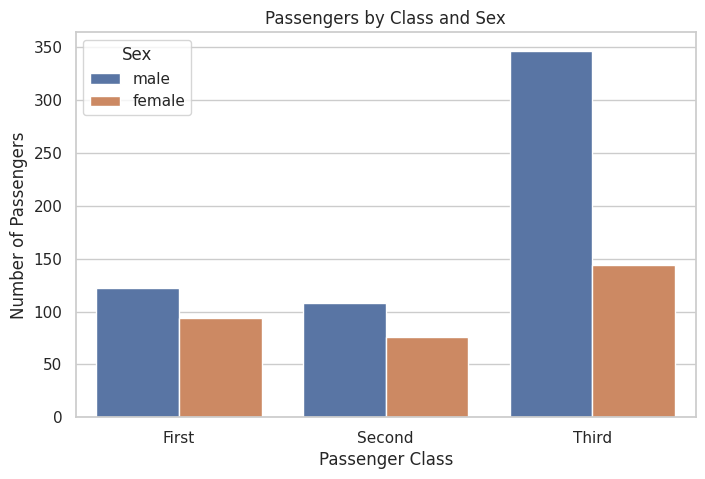

In [23]:
# TASK 1: Countplot

plt.figure(figsize=(8, 5))

sns.countplot(
    data=titanic,
    x="class",
    hue="sex"
)

plt.title("Passengers by Class and Sex")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.legend(title="Sex")

plt.show()

Insight:
The number of passengers differs across passenger classes. The distribution of male and female passengers also varies between the classes.

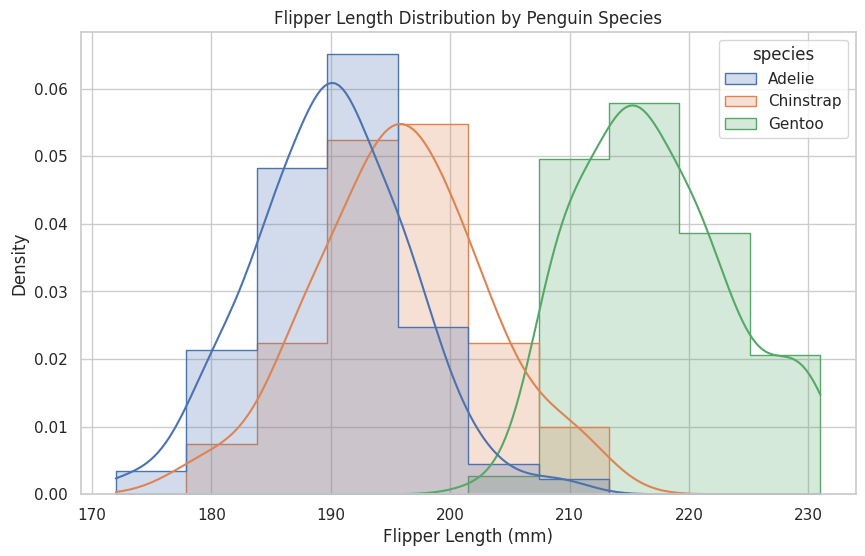

In [24]:
# TASK 2: Histogram with KDE

plt.figure(figsize=(10, 6))

sns.histplot(
    data=penguins,
    x="flipper_length_mm",
    hue="species",
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Flipper Length Distribution by Penguin Species")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Density")

plt.show()

Insight:
The three penguin species show different distributions of flipper length. Some species tend to have longer flippers than others.

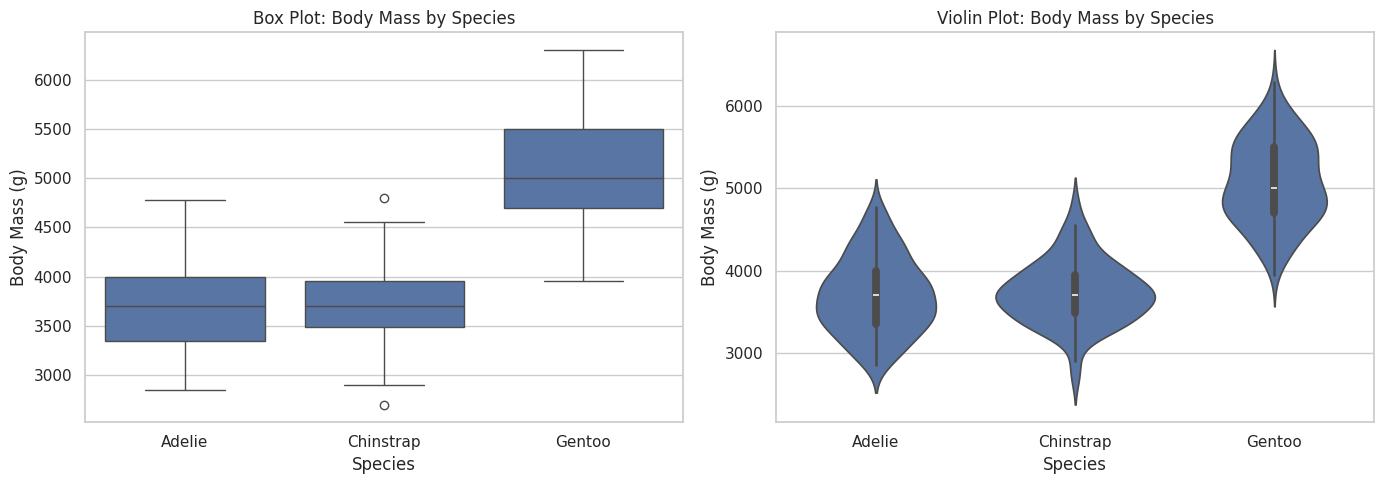

In [25]:
# TASK 3: Box Plot vs Violin Plot

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Box Plot
sns.boxplot(
    data=penguins,
    x="species",
    y="body_mass_g",
    ax=axes[0]
)

axes[0].set_title("Box Plot: Body Mass by Species")
axes[0].set_xlabel("Species")
axes[0].set_ylabel("Body Mass (g)")


# Violin Plot
sns.violinplot(
    data=penguins,
    x="species",
    y="body_mass_g",
    ax=axes[1]
)

axes[1].set_title("Violin Plot: Body Mass by Species")
axes[1].set_xlabel("Species")
axes[1].set_ylabel("Body Mass (g)")


plt.tight_layout()
plt.show()

Insight:
The box plot makes it easier to compare the median, spread and possible outliers. The violin plot shows more information about the shape and density of the distribution.

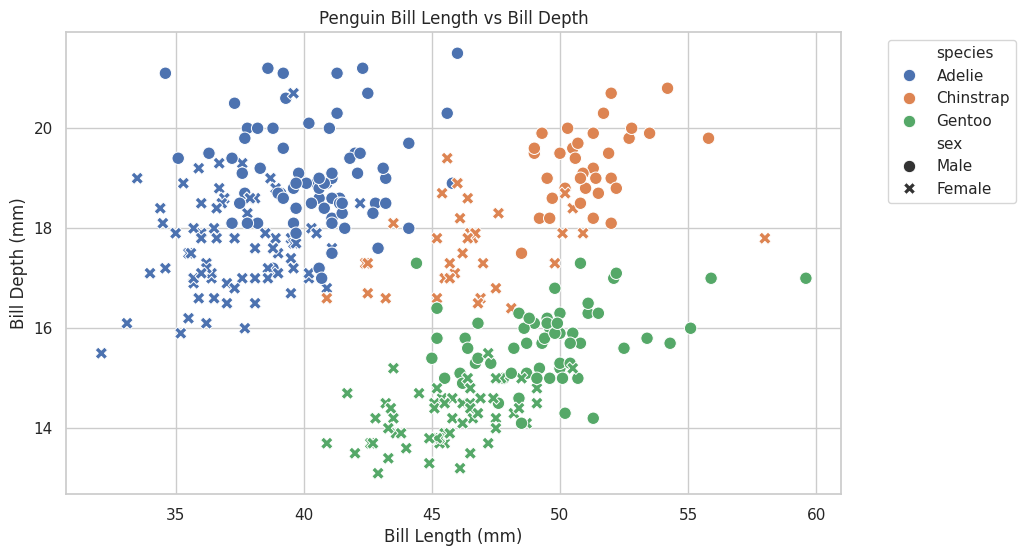

In [26]:
# TASK 4: Scatterplot

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=penguins,
    x="bill_length_mm",
    y="bill_depth_mm",
    hue="species",
    style="sex",
    s=80
)

plt.title("Penguin Bill Length vs Bill Depth")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Bill Depth (mm)")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.show()

Insight:
The scatter plot shows that penguin species occupy different regions based on bill length and bill depth. Sex also contributes to differences within the species.

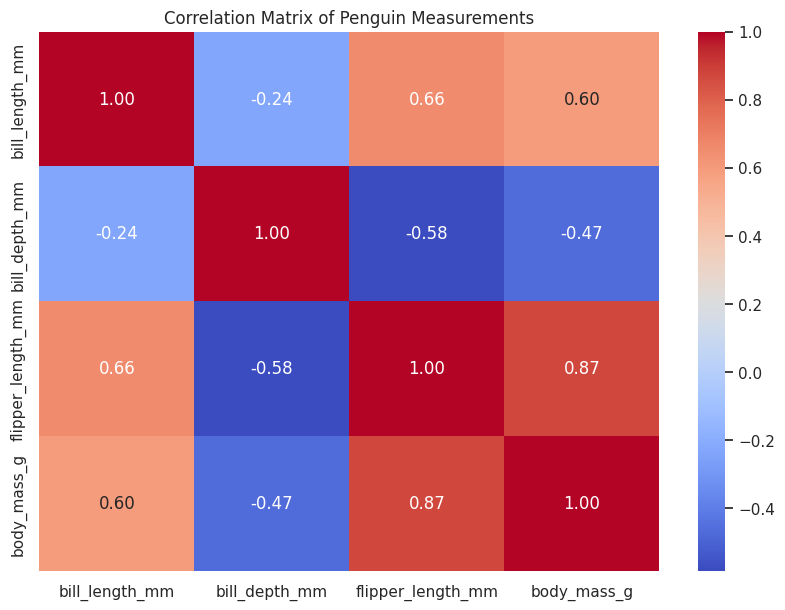

In [27]:
# TASK 5: Heatmap

numeric_data = penguins.select_dtypes(include="number")

correlation_matrix = numeric_data.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Penguin Measurements")

plt.show()

Insight:The heatmap shows the strength and direction of relationships between the numerical variables. Strong positive correlations indicate that two variables tend to increase together, while negative correlations indicate an inverse relationship.

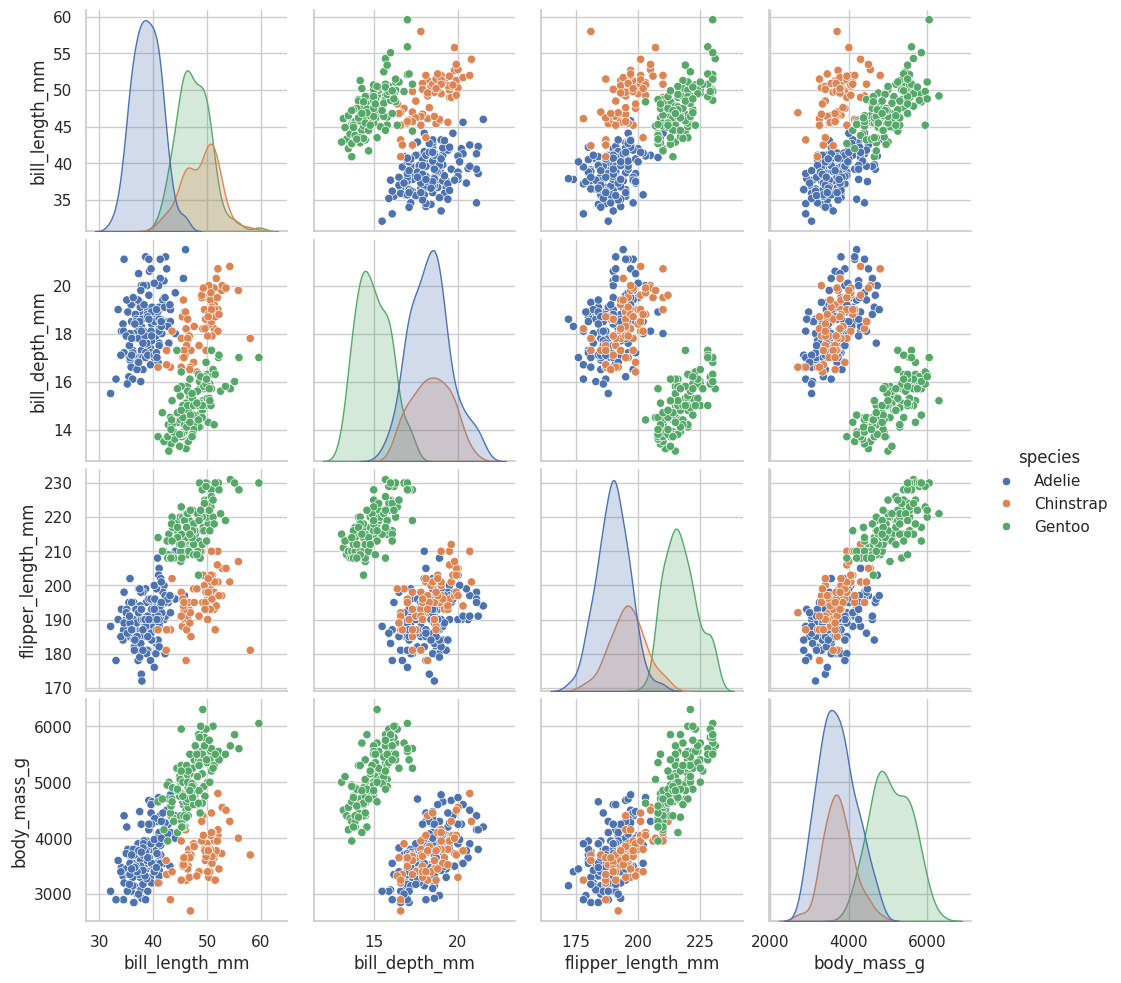

In [28]:
# TASK 6: Pairplot

pairplot_data = penguins[
    [
        "bill_length_mm",
        "bill_depth_mm",
        "flipper_length_mm",
        "body_mass_g",
        "species"
    ]
].dropna()

sns.pairplot(
    pairplot_data,
    hue="species"
)

plt.show()

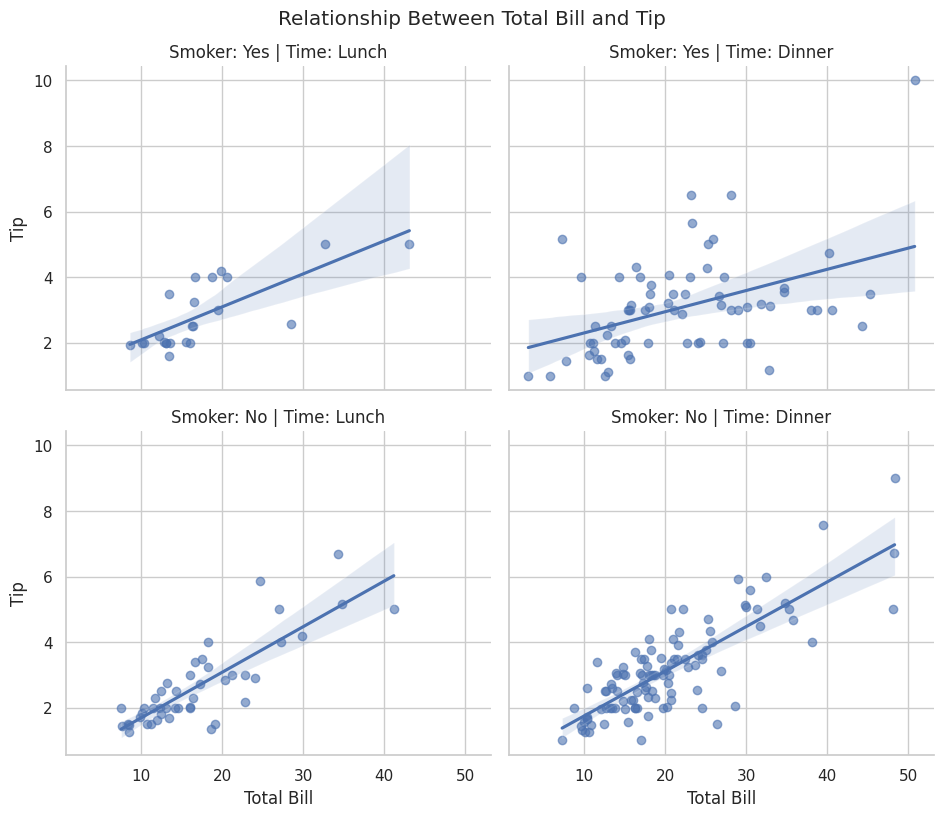

In [29]:
# TASK 7: lmplot

sns.set_theme(
    style="whitegrid",
    context="notebook"
)

plot = sns.lmplot(
    data=tips,
    x="total_bill",
    y="tip",
    col="time",
    row="smoker",
    height=4,
    aspect=1.2,
    scatter_kws={"alpha": 0.6}
)

plot.set_axis_labels(
    "Total Bill",
    "Tip"
)

plot.set_titles(
    row_template="Smoker: {row_name}",
    col_template="Time: {col_name}"
)

plot.fig.suptitle(
    "Relationship Between Total Bill and Tip",
    y=1.02
)

plt.show()

Insight:
There is a positive relationship between total bill and tip. As the total bill increases, the tip generally increases as well, although the strength of the relationship varies between groups.